# SETUP

[TUTORIAL LINK](https://colab.research.google.com/github/google/earthengine-community/blob/master/guides/linked/ee-api-colab-setup.ipynb#scrollTo=v7pD6pDOAhOW)

In [ ]:
import ee
import geemap.core as geemap

In [ ]:
PROJECT_ID = 'still-algebra-425406-v5'

In [ ]:
# Trigger the authentication flow.
ee.Authenticate()

# Initialize the library.
ee.Initialize(project=PROJECT_ID)

In [ ]:
## testing
# Print the elevation of Mount Everest.
dem = ee.Image('USGS/SRTMGL1_003')
xy = ee.Geometry.Point([86.9250, 27.9881])
elev = dem.sample(xy, 30).first().get('elevation').getInfo()
print('Mount Everest elevation (m):', elev)

Mount Everest elevation (m): 8729


In [ ]:
dataset = ee.ImageCollection('LANDSAT/LC09/C02/T1_L2').filterDate(
    '2022-01-01', '2022-02-01'
)


# Applies scaling factors.
def apply_scale_factors(image):
  optical_bands = image.select('SR_B.').multiply(0.0000275).add(-0.2)
  thermal_bands = image.select('ST_B.*').multiply(0.00341802).add(149.0)
  return image.addBands(optical_bands, None, True).addBands(
      thermal_bands, None, True
  )


dataset = dataset.map(apply_scale_factors)

visualization = {
    'bands': ['SR_B4', 'SR_B3', 'SR_B2'],
    'min': 0.0,
    'max': 0.3,
}

m = geemap.Map()
m.set_center(-114.2579, 38.9275, 8)
m.add_layer(dataset, visualization, 'True Color (432)')
m

Map(center=[38.9275, -114.2579], controls=(WidgetControl(options=['position', 'transparent_bg'], position='top…

# GETTING THE DATA

## AOI — Bengaluru

In [ ]:
# Use FAO GAUL admin boundaries to get an accurate city/district polygon
# instead of a hand-drawn box (keeps the analysis reproducible).
admin2 = ee.FeatureCollection('FAO/GAUL/2015/level2')
bengaluru_urban = admin2.filter(
    ee.Filter.And(
        ee.Filter.eq('ADM1_NAME', 'Karnataka'),
        ee.Filter.eq('ADM2_NAME', 'Bangalore Urban')
    )
)
aoi = bengaluru_urban.geometry()

## Load & preprocess Landsat 9

In [ ]:
START_DATE = '2024-01-01'
END_DATE   = '2024-05-31'   # pre-monsoon / summer window shows heat stress best
CLOUD_MAX  = 20

def apply_scale_factors(image):
    optical = image.select('SR_B.').multiply(0.0000275).add(-0.2)
    thermal = image.select('ST_B.*').multiply(0.00341802).add(149.0)
    return image.addBands(optical, None, True).addBands(thermal, None, True)

def mask_clouds(image):
    qa = image.select('QA_PIXEL')
    # Bits: 1=dilated cloud, 2=cirrus, 3=cloud, 4=cloud shadow
    cloud_bit_mask = (1 << 1) | (1 << 2) | (1 << 3) | (1 << 4)
    mask = qa.bitwiseAnd(cloud_bit_mask).eq(0)
    return image.updateMask(mask)

l9 = (ee.ImageCollection('LANDSAT/LC09/C02/T1_L2')
      .filterBounds(aoi)
      .filterDate(START_DATE, END_DATE)
      .filter(ee.Filter.lt('CLOUD_COVER', CLOUD_MAX))
      .map(apply_scale_factors)
      .map(mask_clouds))

print('Scenes used:', l9.size().getInfo())

# Median composite over the window — reduces residual cloud/shadow noise
composite = l9.median().clip(aoi)


Scenes used: 7


## Derived layers

In [ ]:
# --- Land Surface Temperature (Celsius) ---
lst_celsius = composite.select('ST_B10').subtract(273.15).rename('LST_C')

# --- NDVI (vegetation) ---
ndvi = composite.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')

# --- NDBI (built-up index, useful proxy for impervious/urban surface) ---
ndbi = composite.normalizedDifference(['SR_B6', 'SR_B5']).rename('NDBI')

# --- Urban Heat Island anomaly: LST relative to the AOI mean ---
lst_mean = lst_celsius.reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=aoi,
    scale=30,
    maxPixels=1e9
).get('LST_C')

lst_anomaly = lst_celsius.subtract(ee.Image.constant(lst_mean)).rename('LST_anomaly')


## Interactive map

In [ ]:
Map = geemap.Map()
Map.centerObject(aoi, 10)

true_color_vis = {'bands': ['SR_B4', 'SR_B3', 'SR_B2'], 'min': 0.0, 'max': 0.3}
lst_vis = {'min': 20, 'max': 45, 'palette': [
    '040274', '30c8e2', '86e26e', 'ffff2b', 'ff9c2b', 'ff0000'
]}
ndvi_vis = {'min': -0.2, 'max': 0.8, 'palette': ['red', 'yellow', 'green']}
anomaly_vis = {'min': -6, 'max': 6, 'palette': ['0000ff', 'ffffff', 'ff0000']}

Map.addLayer(aoi, {'color': 'black'}, 'Bengaluru Urban boundary', True, 0.4)
Map.addLayer(composite, true_color_vis, 'True Color (432)')
Map.addLayer(lst_celsius, lst_vis, 'Land Surface Temperature (°C)')
Map.addLayer(ndvi, ndvi_vis, 'NDVI')
Map.addLayer(lst_anomaly, anomaly_vis, 'LST anomaly (UHI)')

Map

Map(center=[12.942246211440619, 77.58684946919364], controls=(WidgetControl(options=['position', 'transparent_…

## Composite heat-priority index

In [ ]:
# Normalize each layer 0-1 over the AOI, then combine.
def normalize(img, band_name, aoi, scale=30):
    stats = img.reduceRegion(
        reducer=ee.Reducer.minMax(), geometry=aoi, scale=scale, maxPixels=1e9
    )
    lo = ee.Number(stats.get(f'{band_name}_min'))
    hi = ee.Number(stats.get(f'{band_name}_max'))
    return img.select(band_name).subtract(lo).divide(hi.subtract(lo))

lst_norm  = normalize(lst_celsius, 'LST_C', aoi)
ndvi_norm = normalize(ndvi, 'NDVI', aoi)   # low NDVI = more pressure
ndbi_norm = normalize(ndbi, 'NDBI', aoi)

# Priority = high heat + high built-up + low vegetation
heat_priority = (lst_norm
                  .add(ndbi_norm)
                  .add(ee.Image(1).subtract(ndvi_norm))
                  .divide(3)
                  .rename('heat_priority'))

Map.addLayer(heat_priority, {'min': 0, 'max': 1, 'palette': ['green', 'yellow', 'red']},
             'Heat Priority Index')
Map

Map(center=[12.942246211440619, 77.58684946919364], controls=(WidgetControl(options=['position', 'transparent_…

## Export at 30m to Drive

In [ ]:
# Cast every band to Float32 so nothing is left mismatched
export_bands = (composite
                 .addBands(lst_celsius)
                 .addBands(ndvi)
                 .addBands(ndbi)
                 .addBands(lst_anomaly)
                 .addBands(heat_priority)
                 .select(['LST_C', 'NDVI', 'NDBI', 'LST_anomaly', 'heat_priority'])
                 .toFloat())   # <-- forces uniform Float32 across all bands

asset_id = f'projects/{PROJECT_ID}/assets/bengaluru_uhi_stack_2024'

task = ee.batch.Export.image.toAsset(
    image=export_bands,
    description='Bengaluru_UHI_stack_2024',
    assetId=asset_id,
    region=aoi,
    scale=30,
    crs='EPSG:4326',
    maxPixels=1e9
)
task.start()
print('Asset export started.')

Asset export started.


In [ ]:
tasks = ee.batch.Task.list()
for t in tasks[:5]:
    print(t.status())

{'state': 'FAILED', 'description': 'Bengaluru_UHI_stack_2024', 'priority': 100, 'creation_timestamp_ms': 1789921304687, 'update_timestamp_ms': 1789921311118, 'start_timestamp_ms': 1789921310751, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'error_message': "Cannot overwrite asset 'projects/still-algebra-425406-v5/assets/bengaluru_uhi_stack_2024'.", 'id': 'I3RXBW5NUFPT76PVYAAK5GHA', 'name': 'projects/still-algebra-425406-v5/operations/I3RXBW5NUFPT76PVYAAK5GHA'}
{'state': 'COMPLETED', 'description': 'Bengaluru_UHI_stack_2024', 'priority': 100, 'creation_timestamp_ms': 1789917940858, 'update_timestamp_ms': 1789918053137, 'start_timestamp_ms': 1789917947307, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://code.earthengine.google.com/?asset=projects/still-algebra-425406-v5/assets/bengaluru_uhi_stack_2024'], 'attempt': 1, 'batch_eecu_usage_seconds': 84.51738739013672, 'id': 'IOXAQ6M4UR4Y2JTZUJAJS634', 'name': 'projects/still-algebra-425406-v5/operations/IOXAQ6M4UR4Y2JTZUJAJS634'}
{'

## Quick stats / histogram

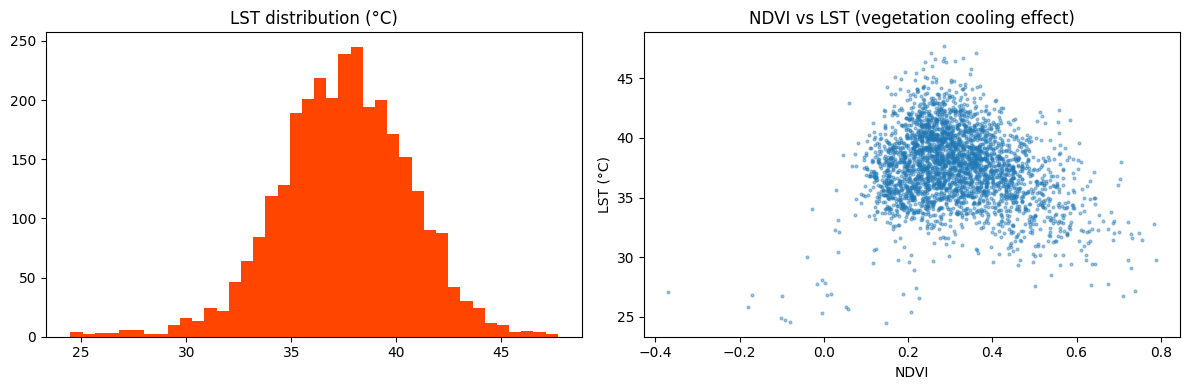

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Sample points for a distribution plot (server-side reduceRegion returns
# a single summary; for a histogram we need pixel samples)
sample = lst_celsius.addBands(ndvi).sample(
    region=aoi, scale=30, numPixels=3000, seed=1, geometries=False
)
sample_list = sample.reduceColumns(
    ee.Reducer.toList().repeat(2), ['LST_C', 'NDVI']
).get('list').getInfo()

lst_vals, ndvi_vals = sample_list

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lst_vals, bins=40, color='orangered')
axes[0].set_title('LST distribution (°C)')
axes[1].scatter(ndvi_vals, lst_vals, s=4, alpha=0.4)
axes[1].set_xlabel('NDVI')
axes[1].set_ylabel('LST (°C)')
axes[1].set_title('NDVI vs LST (vegetation cooling effect)')
plt.tight_layout()
plt.show()